# Falling Rents — Plotting Data for the Web Page

Writes front-end-ready JSON for `src/routes/falling-rents` into `src/data/falling-rents/`.
All analysis and geometry processing happens here so the Svelte components only have to draw.

Each visualization is a numbered `vis` export, mirroring `rising-rents-supply/create_rental_plotting_data.ipynb`.
The analysis these figures come from lives in `explore_falling_rents.ipynb`.

## VIS 1 — Net change in asking rents since 2019 (map)

One spike / arrow per CMA, sized by the **net percentage change in asking rent** between the first quarter of the
StatCan series (Q1 2019) and the latest quarter. This is deliberately the *net* figure, not the post-peak decline:
the point of the map is that, even after the recent softening, rents are still far above where they were in 2019.

- Series: StatCan Table 46-10-0092-01, 2-bedroom apartment asking rent (same headline series as `explore_falling_rents.ipynb`).
- Cities: every CMA with at least `MIN_QUARTERS` quarters of data and a Q1 2019 observation.
- Geometry: StatCan cartographic provincial boundaries, projected to Lambert conformal conic (EPSG:3347), cropped to the
  populated south, heavily simplified, and shipped as plain GeoJSON in **kilometres** so the front end can use
  `d3.geoIdentity()` with no projection work.
- Frames: one national frame plus three zoomed **insets** — Southern BC, Southern Ontario and Southern Quebec —
  where cities are too tightly packed to read at national scale. The two corridor insets are **rotated** (30° clockwise) so the
  Windsor–Québec City corridor runs left-to-right and fits a short, wide box.
- Arrow angle: chosen here by counting arrow overlaps at each candidate tilt, rather than by eye (see "Choosing the arrow tilt").

In [1]:
from itertools import combinations
from pathlib import Path
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Transformer
from shapely import affinity
from shapely.geometry import MultiPolygon, Polygon, box, mapping
from shapely.geometry.polygon import orient

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# ── Paths ─────────────────────────────────────────────────────────────
ASKING_ROOT   = Path('../../data/statscan-quarterly-rental-clean/can-cma-all')
PROVINCE_PATH = Path('../../data/geo/canada_provinces.geojson')   # StatCan provincial cartographic boundaries
OUT_DIR       = Path('../../src/data/falling-rents')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Series definition (matches explore_falling_rents.ipynb) ──────────
BED_COLUMN       = 'Apt 2br'
BED_LABEL        = '2-bedroom apartment'
BASELINE_QUARTER = 'Q1 2019'
MIN_QUARTERS     = 8

# ── Geometry settings ────────────────────────────────────────────────
PROJ_CRS          = 'EPSG:3347'    # StatCan Lambert conformal conic
MAIN_SIMPLIFY_KM  = 4.0            # shoreline simplification, national frame
INSET_SIMPLIFY_KM = 1.5            # finer, because insets are drawn 2.5-4x larger
MIN_ISLAND_KM2    = 3000           # national frame: drop islands smaller than this (keeps PEI, Cape Breton, Vancouver Is., Haida Gwaii, Anticosti)
INSET_MIN_ISLAND_KM2 = 150         # insets are drawn much larger, so keep small islands that matter (Island of Montreal ~690 km2, Salt Spring ~180 km2)

# Arrows are drawn in four size classes (length / thickness / colour per class). These mirror CLASS_BREAKS / CLASS_LEN_FRAC in CanadaGlyphMap.svelte.
CLASS_BREAKS   = [25, 50, 75]               # % change; four classes: <25, 25-50, 50-75, 75+
CLASS_LEN_FRAC = [0.36, 0.58, 0.80, 1.0]    # arrow length as a share of the longest arrow
# The map's "after inflation" view uses its own breaks, because real changes are much smaller (median ~21%, one city below zero, which the page
# draws as a separate downward 'decline' arrow rather than a class).
CLASS_BREAKS_REAL = [10, 25, 40]             # real % change; classes: <10, 10-25, 25-40, 40+

# National frame: west edge just past Vancouver Island, east edge just past Newfoundland, south edge under Point Pelee.
# The north edge is a hard crop a little above the northernmost cities (in this projection Edmonton / St. John's, ~2,170 km).
# The east pad leaves room for tilted arrows near St. John's.
MAIN_PAD_KM = dict(west=140, east=260, north_above_cities=430)

# ── Insets ────────────────────────────────────────────────────────────
# Each inset zooms on a padded box around its anchor cities.
#   rotation   degrees counter-clockwise applied to the map in that inset (negative = clockwise), to fit a diagonal area to a wide box
#   pad_km     breathing room around the anchor cities, measured in the (rotated) inset frame
#   row        which row it sits in on narrow screens (desktop puts all insets in one row, in `order`)
#   zoom       box width = visible width x zoom x the row's shared scale, so denser areas can be magnified more
INSETS = [
    # Kamloops and Kelowna are far enough inland to read fine at national scale, so this inset zooms on the
    # Vancouver Island / Lower Mainland cluster instead (zoom 1.9x the shared inset scale, since it is the densest).
    dict(id='bc', title='Southern BC', rotation=0, order=0, row=0, zoom=1.9,
         anchors=['victoria', 'nanaimo', 'vancouver', 'abbotsford-mission', 'chilliwack'],
         pad_km=dict(west=95, east=95, south=75, north=60)),
    dict(id='on', title='Southern Ontario', rotation=-30, order=1, row=1, zoom=1.0,
         anchors=['windsor', 'london', 'kitchener-cambridge-waterloo', 'guelph', 'brantford', 'st. catharines-niagara',
                  'hamilton', 'toronto', 'barrie', 'oshawa', 'peterborough', 'belleville-quinte west', 'kingston',
                  'ottawa', 'gatineau'],
         pad_km=dict(west=85, east=85, south=80, north=45)),
    dict(id='qc', title='Southern Quebec', rotation=-30, order=2, row=0, zoom=1.0,
         anchors=['ottawa', 'gatineau', 'montreal', 'sherbrooke', 'drummondville', 'quebec'],
         pad_km=dict(west=95, east=95, south=80, north=45)),
]
GENEROUS_KM = 220   # geometry is clipped this far beyond the visible box so the page can show a taller/wider box without gaps

# ── City centres (lat, lon) and display names ────────────────────────
# Neither the rent files nor data/reference carry coordinates, so city-centre points
# are listed here. Spikes are drawn at these points, not at CMA centroids.
CITY_COORDS = {
    'abbotsford-mission': (49.05, -122.30), 'barrie': (44.39, -79.69),
    'belleville-quinte west': (44.16, -77.38), 'brantford': (43.14, -80.26),
    'calgary': (51.05, -114.07), 'chilliwack': (49.16, -121.95),
    'drummondville': (45.88, -72.48), 'edmonton': (53.55, -113.49),
    'fredericton': (45.96, -66.64), 'gatineau': (45.48, -75.65),
    'greater sudbury': (46.49, -81.00), 'guelph': (43.55, -80.25),
    'halifax': (44.65, -63.58), 'hamilton': (43.26, -79.87),
    'kamloops': (50.67, -120.33), 'kelowna': (49.89, -119.50),
    'kingston': (44.23, -76.48), 'kitchener-cambridge-waterloo': (43.45, -80.49),
    'lethbridge': (49.69, -112.84), 'london': (42.98, -81.25),
    'moncton': (46.09, -64.78), 'montreal': (45.50, -73.57),
    'nanaimo': (49.17, -123.94), 'oshawa': (43.90, -78.85),
    'ottawa': (45.42, -75.70), 'peterborough': (44.30, -78.32),
    'quebec': (46.81, -71.21), 'red deer': (52.27, -113.81),
    'regina': (50.45, -104.61), 'saguenay': (48.43, -71.07),
    'saint john': (45.27, -66.06), 'saskatoon': (52.13, -106.67),
    'sherbrooke': (45.40, -71.89), 'st. catharines-niagara': (43.16, -79.24),
    "st. john's": (47.56, -52.71), 'thunder bay': (48.38, -89.25),
    'toronto': (43.65, -79.38), 'trois-rivieres': (46.34, -72.54),
    'vancouver': (49.28, -123.12), 'victoria': (48.43, -123.37),
    'windsor': (42.32, -83.04), 'winnipeg': (49.90, -97.14),
}

DISPLAY_NAME = {
    'abbotsford-mission': 'Abbotsford–Mission', 'belleville-quinte west': 'Belleville–Quinte West',
    'kitchener-cambridge-waterloo': 'Kitchener–Cambridge–Waterloo', 'montreal': 'Montréal',
    'quebec': 'Québec City', 'saguenay': 'Saguenay', 'st. catharines-niagara': 'St. Catharines–Niagara',
    "st. john's": "St. John's", 'trois-rivieres': 'Trois-Rivières', 'greater sudbury': 'Greater Sudbury',
    'saint john': 'Saint John', 'red deer': 'Red Deer', 'thunder bay': 'Thunder Bay',
}

CMA_PROVINCE = pd.read_csv('../../data/reference/cma_to_province.csv').set_index('cma')['province'].to_dict()

# Label priority (same for every frame): the biggest metropolitan areas first, then any city with a large increase,
# then everything else by size of increase. The page tries labels in this order, puts each beside the city's own dot,
# and silently skips any whose text would collide with an arrow or another label (hover / tap still names every city).
MAJOR_CITIES = ['toronto', 'montreal', 'vancouver', 'calgary', 'edmonton', 'ottawa', 'winnipeg', 'quebec', 'hamilton',
                'kitchener-cambridge-waterloo', 'london', 'halifax', 'st. catharines-niagara', 'oshawa', 'victoria', 'windsor',
                'saskatoon', 'regina', "st. john's", 'sherbrooke', 'barrie', 'kelowna', 'abbotsford-mission', 'kingston']
# Labels are kept to the major cities plus the prominent cases, so the map stays readable: every city still has a hover / tap pop-up.
# Prominent cases: the biggest increases (Sherbrooke, Halifax, St. John's, Gatineau; Drummondville, the biggest, is too tightly packed among its neighbours for a clear spot) and Toronto (smallest increase; the only decline after inflation).
# Per frame; the front end places each name beside its own arrow and leaves it off if there is no clear spot.
LABEL_CITIES = {
    'main': ['calgary', 'edmonton', 'winnipeg', 'halifax', "st. john's"],
    'bc':   ['vancouver', 'victoria'],
    'on':   ['toronto', 'ottawa', 'london', 'windsor'],
    'qc':   ['montreal', 'quebec', 'sherbrooke', 'gatineau'],
}

LABEL_TEXT = {('bc', 'abbotsford-mission'): 'Abbotsford', ('on', 'kitchener-cambridge-waterloo'): 'Kitchener',
              ('on', 'st. catharines-niagara'): 'St. Catharines', ('on', 'belleville-quinte west'): 'Belleville'}

# Ottawa and Gatineau centres are ~4 km apart, which would stack their glyphs into one.
# Nudge them apart (km) so both stay visible; hover/tap still names each correctly.
NUDGE_KM = {'ottawa': (-9, -4), 'gatineau': (9, 4)}

### Net change per city

`net_change_pct = (latest / Q1 2019 − 1) × 100`, using the 2-bedroom asking-rent series. The Canada-wide figure uses StatCan's own
"All CMAs" aggregate (`all.csv`), the same national series used in `explore_falling_rents.ipynb`.

In [3]:
def load_series(fp: Path) -> pd.Series:
    df = pd.read_csv(fp)
    return df.set_index('Quarter')[BED_COLUMN].dropna()


def quarter_key(label: str):
    q, y = label.split()
    return (int(y), int(q[1]))


rows, skipped = [], []
for fp in sorted(ASKING_ROOT.glob('*.csv')):
    if fp.stem == 'all':
        continue
    s = load_series(fp)
    if len(s) < MIN_QUARTERS or BASELINE_QUARTER not in s.index:
        skipped.append(fp.stem)
        continue
    s = s.loc[sorted(s.index, key=quarter_key)]
    base, latest = float(s[BASELINE_QUARTER]), float(s.iloc[-1])
    rows.append({
        'key': fp.stem,
        'latest_quarter': s.index[-1],
        'base_rent': round(base),
        'latest_rent': round(latest),
        'pct_change': round((latest / base - 1) * 100, 1),
    })

net = pd.DataFrame(rows)
assert net['latest_quarter'].nunique() == 1, 'cities disagree on the latest quarter'
LATEST_QUARTER = net['latest_quarter'].iloc[0]

nat = load_series(ASKING_ROOT / 'all.csv')
nat_pct = round((nat.iloc[-1] / nat[BASELINE_QUARTER] - 1) * 100, 1)

print(f'{len(net)} cities with data, {BASELINE_QUARTER} -> {LATEST_QUARTER}')
print(f'skipped (too little {BED_LABEL} data): {skipped}')
print(f'Canada-wide (All CMAs): ${nat[BASELINE_QUARTER]:,.0f} -> ${nat.iloc[-1]:,.0f}  ({nat_pct:+.1f}%)')
pc = net['pct_change']
print(f'median {pc.median():.1f}%  |  range {pc.min():.1f}% to {pc.max():.1f}%')
net.sort_values('pct_change', ascending=False).head(5)

40 cities with data, Q1 2019 -> Q1 2026
skipped (too little 2-bedroom apartment data): ['saguenay', 'trois-rivieres']
Canada-wide (All CMAs): $1,520 -> $2,150  (+41.4%)
median 47.0%  |  range 3.9% to 105.0%


,key,latest_quarter,base_rent,latest_rent,pct_change
6,drummondville,Q1 2026,600,1230,105.0
31,sherbrooke,Q1 2026,660,1250,89.4
12,halifax,Q1 2026,1290,2350,82.2
33,st. john's,Q1 2026,900,1570,74.4
20,moncton,Q1 2026,860,1470,70.9


### Project city points and build the frames

Everything is projected to EPSG:3347 and expressed in **km**, north-up. The front end flips y when it draws (`geoIdentity().reflectY(true)`).
Each inset gets its own coordinates: the same projected points rotated about the inset's centre.

In [4]:
to_proj = Transformer.from_crs('EPSG:4326', PROJ_CRS, always_xy=True)

def project_km(lat, lon):
    x, y = to_proj.transform(lon, lat)
    return x / 1000, y / 1000

def city_xy(key):
    x, y = project_km(*CITY_COORDS[key])
    dx, dy = NUDGE_KM.get(key, (0, 0))
    return np.array([x + dx, y + dy])

net['xy'] = [city_xy(k) for k in net['key']]
net['city'] = [DISPLAY_NAME.get(k, k.title()) for k in net['key']]
net['province'] = net['key'].map(CMA_PROVINCE)
assert net['province'].notna().all()
net = net.sort_values('pct_change', ascending=False).reset_index(drop=True)   # row order == `cities` order in the JSON
key_to_idx = {k: i for i, k in enumerate(net['key'])}
XY = np.vstack(net['xy'])

def rotate_pts(pts, deg, origin):
    t = np.radians(deg)
    R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return (np.atleast_2d(pts) - origin) @ R.T + origin

def label_rank(key):
    """Sort key (placement priority): major cities (by size) first, then the prominent cases by increase."""
    pct = float(net.loc[key_to_idx[key], 'pct_change'])
    if key in MAJOR_CITIES:
        return (0, MAJOR_CITIES.index(key))
    return (1, -pct)

def label_entries(frame_id, idxs):
    out = []
    for key in sorted(key_to_idx, key=label_rank):
        i = key_to_idx[key]
        if key not in LABEL_CITIES.get(frame_id, []):
            continue
        if i in idxs:
            entry = {'i': i}
            if key in MAJOR_CITIES:
                entry['major'] = True     # the page may let a major city's label cross a neighbour's arrow rather than drop it
            if (frame_id, key) in LABEL_TEXT:
                entry['text'] = LABEL_TEXT[(frame_id, key)]
            out.append(entry)
    return out

# ── National frame (km) ──────────────────────────────────────────────
main_extent = [XY[:, 0].min() - MAIN_PAD_KM['west'], city_xy('windsor')[1] - 140,
               XY[:, 0].max() + MAIN_PAD_KM['east'], XY[:, 1].max() + MAIN_PAD_KM['north_above_cities']]

# ── Inset frames ─────────────────────────────────────────────────────
for ins in INSETS:
    anchors = np.array([city_xy(k) for k in ins['anchors']])
    ins['origin'] = anchors.mean(axis=0)
    a_rot = rotate_pts(anchors, ins['rotation'], ins['origin'])
    pad = ins['pad_km']
    ins['fit'] = [a_rot[:, 0].min() - pad['west'], a_rot[:, 1].min() - pad['south'],
                  a_rot[:, 0].max() + pad['east'], a_rot[:, 1].max() + pad['north']]
    ins['extent'] = [ins['fit'][0] - GENEROUS_KM, ins['fit'][1] - GENEROUS_KM,
                     ins['fit'][2] + GENEROUS_KM, ins['fit'][3] + GENEROUS_KM]
    pts_rot = rotate_pts(XY, ins['rotation'], ins['origin'])
    f = ins['fit']
    ins['member_idx'] = [i for i, (x, y) in enumerate(pts_rot) if f[0] <= x <= f[2] and f[1] <= y <= f[3]]
    ins['pts_rot'] = pts_rot
    # the visible box, drawn back on the national map as a (rotated) outline
    ins['region'] = rotate_pts(np.array(box(*f).exterior.coords)[:-1], -ins['rotation'], ins['origin'])
    print(f"{ins['id']:3s} rot {ins['rotation']:4d}°  fit {f[2]-f[0]:.0f} x {f[3]-f[1]:.0f} km  "
          f"{len(ins['member_idx'])} cities: {sorted(net.loc[ins['member_idx'], 'city'])}")

in_any_inset = set(i for ins in INSETS for i in ins['member_idx'])
print(f"national frame: {main_extent[2]-main_extent[0]:.0f} x {main_extent[3]-main_extent[1]:.0f} km;  "
      f"{len(in_any_inset)} of {len(net)} cities also appear in an inset")

bc  rot    0°  fit 320 x 227 km  5 cities: ['Abbotsford–Mission', 'Chilliwack', 'Nanaimo', 'Vancouver', 'Victoria']
on  rot  -30°  fit 870 x 290 km  15 cities: ['Barrie', 'Belleville–Quinte West', 'Brantford', 'Gatineau', 'Guelph', 'Hamilton', 'Kingston', 'Kitchener–Cambridge–Waterloo', 'London', 'Oshawa', 'Ottawa', 'Peterborough', 'St. Catharines–Niagara', 'Toronto', 'Windsor']
qc  rot  -30°  fit 578 x 270 km  7 cities: ['Drummondville', 'Gatineau', 'Kingston', 'Montréal', 'Ottawa', 'Québec City', 'Sherbrooke']
national frame: 5423 x 2011 km;  24 of 40 cities also appear in an inset


In [5]:
prov = gpd.read_file(PROVINCE_PATH).to_crs(PROJ_CRS)
prov['geometry'] = prov.geometry.scale(xfact=0.001, yfact=0.001, origin=(0, 0))   # work in km from here on
prov = prov[['PRENAME', 'PREABBR', 'geometry']].rename(columns={'PRENAME': 'name', 'PREABBR': 'abbr'})


def make_frame(clip_poly, tolerance_km, rotation=0, origin=None, min_island_km2=MIN_ISLAND_KM2):
    """Clip provinces to a polygon (given in the *frame's* coordinates), simplify across shared borders, drop small islands.
    For rotated insets the clip polygon is rotated back into map space, intersected there, then the result is rotated forward."""
    simplified = prov.geometry.simplify_coverage(tolerance_km)
    clip = affinity.rotate(clip_poly, -rotation, origin=tuple(origin)) if rotation else clip_poly
    parts = []
    for name, abbr, geom in zip(prov.name, prov.abbr, simplified):
        g = geom.intersection(clip)
        if g.is_empty:
            continue
        polys = [p for p in (g.geoms if hasattr(g, 'geoms') else [g])
                 if p.geom_type == 'Polygon' and p.area >= min_island_km2]
        if not polys:
            continue
        u = gpd.GeoSeries(polys).union_all()
        if rotation:
            u = affinity.rotate(u, rotation, origin=tuple(origin))
        parts.append({'name': name, 'abbr': abbr, 'geometry': u})
    return gpd.GeoDataFrame(parts, crs=PROJ_CRS)


def to_feature_collection(gdf):
    # coordinates rounded to 0.1 km (~100 m): far below what's visible at any display size
    feats = []
    for name, abbr, geom in zip(gdf['name'], gdf['abbr'], gdf.geometry):
        # consistent ring winding (exterior CCW, holes CW) so SVG fills never invert
        polys = list(geom.geoms) if hasattr(geom, 'geoms') else [geom]
        gj = mapping(MultiPolygon([orient(p, 1.0) for p in polys]))
        def rnd(c):
            return [round(c[0], 1), round(c[1], 1)] if isinstance(c[0], (int, float)) else [rnd(i) for i in c]
        gj = {'type': gj['type'], 'coordinates': rnd(gj['coordinates'])}
        feats.append({'type': 'Feature', 'properties': {'name': name, 'abbr': abbr}, 'geometry': gj})
    return {'type': 'FeatureCollection', 'features': feats}


def n_polys(gdf):
    return sum(len(g.geoms) if hasattr(g, 'geoms') else 1 for g in gdf.geometry)

main_prov = make_frame(box(*main_extent), MAIN_SIMPLIFY_KM)
print(f'main: {len(main_prov)} provinces, {n_polys(main_prov)} polygons')
for ins in INSETS:
    ins['prov'] = make_frame(box(*ins['extent']), INSET_SIMPLIFY_KM, ins['rotation'], ins['origin'], INSET_MIN_ISLAND_KM2)
    print(f"{ins['id']}: {len(ins['prov'])} provinces, {n_polys(ins['prov'])} polygons")

main: 10 provinces, 14 polygons
bc: 1 provinces, 9 polygons
on: 2 provinces, 9 polygons
qc: 3 provinces, 9 polygons


### Inflation adjustment (shared by the map and VIS 2)

The page lets readers switch between **nominal** change and change **after inflation**. To deflate, this reuses the method in
`explore_falling_rents.ipynb`: each province's annual CPI (`data/reference/cpi_by_province.csv`) is placed at that year's Q2 and
linearly interpolated to quarters; Canada uses the national CPI. A rent in any quarter is expressed in dollars of the latest CPI quarter.

CPI is only published through 2025, so quarters after the last CPI quarter are held at that level: the latest rent is left as is, and the
real change is slightly *understated* for the most recent three quarters (it ignores 2025 H2 – 2026 Q1 inflation).

In [6]:
# ── Inflation adjustment (shared with VIS 2) ─────────────────────────
CPI_PATH = Path('../../data/reference/cpi_by_province.csv')
cpi_annual = pd.read_csv(CPI_PATH).set_index('Year')


def cpi_quarterly(annual: pd.Series) -> pd.Series:
    """Annual CPI -> quarterly: the annual value sits at Q2, linearly interpolated between years (as in explore_falling_rents.ipynb)."""
    knots = pd.PeriodIndex([pd.Period(f'{y}Q2') for y in annual.index], freq='Q')
    s = pd.Series(annual.values, index=knots)
    return s.reindex(pd.period_range(knots.min(), knots.max(), freq='Q')).interpolate('linear').ffill().bfill()


cpi_q = {c: cpi_quarterly(cpi_annual[c]) for c in cpi_annual.columns}
REAL_YEAR = int(cpi_q['Canada'].index.max().year)           # rents are expressed in dollars of this CPI year


def real_factor(column: str, quarter_label: str) -> float:
    """Multiply a nominal rent in `quarter_label` by this to express it in latest-CPI-quarter dollars (quarters past the CPI series are held at its end)."""
    s = cpi_q[column]
    q, y = quarter_label.split()
    p = min(pd.Period(f'{y}{q}', freq='Q'), s.index.max())
    return float(s[s.index.max()] / s[p])


f0 = [real_factor(CMA_PROVINCE[k], BASELINE_QUARTER) for k in net['key']]
f1 = [real_factor(CMA_PROVINCE[k], LATEST_QUARTER) for k in net['key']]
net['real_base_rent'] = [int(round(b * f)) for b, f in zip(net['base_rent'], f0)]                       # starting rent in REAL_YEAR dollars
net['real_pct'] = [round(((l * g) / (b * f) - 1) * 100, 1) for l, g, b, f in zip(net['latest_rent'], f1, net['base_rent'], f0)]

print(f'CPI base: {REAL_YEAR} dollars')
print(f"real net change: median {net['real_pct'].median():.1f}%, range {net['real_pct'].min():.1f}% to {net['real_pct'].max():.1f}%  "
      f"(nominal: median {net['pct_change'].median():.1f}%)")
print('below zero after inflation:', list(net.loc[net['real_pct'] < 0, 'city']))
edges = [0] + CLASS_BREAKS_REAL + [np.inf]
print('cities per real class', {f'{lo}-{hi}': int(((net['real_pct'] >= lo) & (net['real_pct'] < hi)).sum()) for lo, hi in zip(edges[:-1], edges[1:])},
      '| decline:', int((net['real_pct'] < 0).sum()))

CPI base: 2025 dollars
real net change: median 21.4%, range -14.1% to 66.8%  (nominal: median 47.0%)
below zero after inflation: ['Toronto']
cities per real class {'0-10': 2, '10-25': 21, '25-40': 10, '40-inf': 6} | decline: 1


### Choosing the arrow tilt

Arrows collide when a city's arrow points at a neighbour — Alberta's cities line up about 27° off vertical, the Windsor–Québec corridor about 49°,
so any single tilt helps one region and hurts another. Rather than pick by eye, count overlapping arrow pairs (segments within `THRESH_PX`)
at every candidate tilt, in every frame, at both a desktop and a phone layout, and take the minimum.

Pixel sizes mirror the page's layout rules (length scale and zoom) closely enough to rank angles; they are not exact.
Cities that sit inside an inset region are drawn faintly on the national map and are excluded from its count.

In [7]:
THRESH_PX = 3.5
MAX_LEN_SPEC = lambda w: min(70, max(38, w * 0.10))      # px length of the longest arrow at map width w (mirrors the page)
vals = net['pct_change'].to_numpy()
class_idx = np.array([sum(v >= b for b in CLASS_BREAKS) for v in vals])
len_frac = np.array(CLASS_LEN_FRAC)[class_idx]               # arrows come in four lengths, not a continuous scale


def seg_dist(a0, a1, b0, b1):
    def pt_seg(p, q0, q1):
        d = q1 - q0
        t = np.clip(np.dot(p - q0, d) / max(np.dot(d, d), 1e-9), 0, 1)
        return np.linalg.norm(p - (q0 + t * d))
    def ccw(a, b, c):
        return (c[1] - a[1]) * (b[0] - a[0]) - (b[1] - a[1]) * (c[0] - a[0])
    if ccw(a0, b0, b1) * ccw(a1, b0, b1) < 0 and ccw(a0, a1, b0) * ccw(a0, a1, b1) < 0:
        return 0.0
    return min(pt_seg(a0, b0, b1), pt_seg(a1, b0, b1), pt_seg(b0, a0, a1), pt_seg(b1, a0, a1))


def overlaps(pts_km, idxs, k, max_len, tilt):
    t = np.radians(tilt)
    u = np.array([np.sin(t), -np.cos(t)])                 # screen coords, y down
    base = np.column_stack([pts_km[:, 0] * k, -pts_km[:, 1] * k])[idxs]
    tips = base + np.outer(len_frac[idxs] * max_len, u)
    return sum(seg_dist(base[a], tips[a], base[b], tips[b]) < THRESH_PX for a, b in combinations(range(len(idxs)), 2))


def total_overlaps(tilt):
    total = {}
    for label, W in [('desktop', 700), ('phone', 360)]:
        inner = W - 24
        k_main = inner / (main_extent[2] - main_extent[0])
        L = MAX_LEN_SPEC(W)
        n = overlaps(XY, [i for i in range(len(net)) if i not in in_any_inset], k_main, L, tilt)
        rows = [INSETS] if W >= 600 else [[i for i in INSETS if i['row'] == r] for r in (0, 1)]
        for row in rows:
            fit_w = sum((i['fit'][2] - i['fit'][0]) * i['zoom'] for i in row)
            k_base = (inner - 8 * (len(row) - 1) - 12 * len(row)) / fit_w
            for i in row:
                n += overlaps(i['pts_rot'], i['member_idx'], k_base * i['zoom'], L, tilt)
        total[label] = n
    return total


TILTS = list(range(-45, 50, 5))
table = pd.DataFrame({t: total_overlaps(t) for t in TILTS}).T
table['total'] = table.sum(axis=1)
table.index.name = 'tilt_deg'
# Only consider up-right leans (the conventional "increase" direction) that look like an arrow map but not a heavy slant:
# below MIN_LEAN arrows are hard to tell from the spike map, above MAX_LEAN they stop reading as "up". 10 deg keeps them visibly
# leaning while taking little horizontal room. Fewest overlaps wins; ties go to the gentler angle.
MIN_LEAN, MAX_LEAN = 10, 30
cand = table.loc[[t for t in table.index if MIN_LEAN <= t <= MAX_LEAN], ['total']].reset_index()
best = int(cand.sort_values(['total', 'tilt_deg']).iloc[0]['tilt_deg'])
# The overlap count picks the gentlest lean that avoids collisions (`best`), but the arrows read more clearly as an arrow map
# with a steeper lean, and the count barely changes (a gentler lean also keeps Alberta's north-south line of cities from stacking its arrows), so the page uses a chosen angle. Set to None to use `best`.
ARROW_TILT_OVERRIDE = 15
ARROW_TILT_DEG = best if ARROW_TILT_OVERRIDE is None else ARROW_TILT_OVERRIDE
print('overlapping arrow pairs by tilt (negative = leans left / up-left)')
print(table.T.to_string())
print()
print(f'lowest-overlap tilt: {best} deg ({int(table.loc[best, "total"])} overlapping pairs; best up-right lean between {MIN_LEAN} and {MAX_LEAN} deg).  '
      f'Unconstrained minimum: {int(table["total"].idxmin())} deg ({int(table["total"].min())} pairs).  Previous +25 deg: {int(table.loc[25, "total"])} pairs.')
print(f'page uses {ARROW_TILT_DEG} deg: {int(table.loc[ARROW_TILT_DEG, "total"])} overlapping pairs (desktop {int(table.loc[ARROW_TILT_DEG, "desktop"])}, phone {int(table.loc[ARROW_TILT_DEG, "phone"])})')

overlapping arrow pairs by tilt (negative = leans left / up-left)
tilt_deg  -45  -40  -35  -30  -25  -20  -15  -10  -5    0    5    10   15   20   25   30   35   40   45
desktop     3    4    4    4    5    5    4    4    3    4    6    3    3    4    6    7    7    5    2
phone       4    5    6    5    6    7    6    3    4    6    7    7    7    6    5    5    4    4    4
total       7    9   10    9   11   12   10    7    7   10   13   10   10   10   11   12   11    9    6

lowest-overlap tilt: 10 deg (10 overlapping pairs; best up-right lean between 10 and 30 deg).  Unconstrained minimum: 45 deg (6 pairs).  Previous +25 deg: 11 pairs.
page uses 15 deg: 10 overlapping pairs (desktop 3, phone 7)


### Labels

For each frame: the cities that appear in it (`points`, in that frame's coordinates) and the order in which the page should try to label them.

In [8]:
frames = []

frames.append({
    'id': 'main', 'title': None, 'extent': [round(v, 1) for v in main_extent],
    'provinces': to_feature_collection(main_prov),
    'points': [{'i': i, 'x': round(float(x), 1), 'y': round(float(y), 1), 'in_inset': i in in_any_inset}
               for i, (x, y) in enumerate(XY)],
    'labels': label_entries('main', set(range(len(net)))),
})

for ins in INSETS:
    members = set(ins['member_idx'])
    frames.append({
        'id': ins['id'], 'title': ins['title'], 'rotation': ins['rotation'], 'order': ins['order'], 'row': ins['row'], 'zoom': ins['zoom'],
        'fit': [round(v, 1) for v in ins['fit']],
        'extent': [round(v, 1) for v in ins['extent']],
        'region': [[round(float(x), 1), round(float(y), 1)] for x, y in ins['region']],
        'provinces': to_feature_collection(ins['prov']),
        'points': [{'i': i, 'x': round(float(ins['pts_rot'][i][0]), 1), 'y': round(float(ins['pts_rot'][i][1]), 1)}
                   for i in ins['member_idx']],
        'labels': label_entries(ins['id'], members),
    })
print({f['id']: (len(f['points']), len(f['labels'])) for f in frames})

{'main': (40, 5), 'bc': (5, 2), 'on': (15, 4), 'qc': (7, 4)}


### Quick visual check

Static preview of every frame (the real graphic is drawn in Svelte). Dots are city points; arrows use the chosen tilt and a nominal length scale.

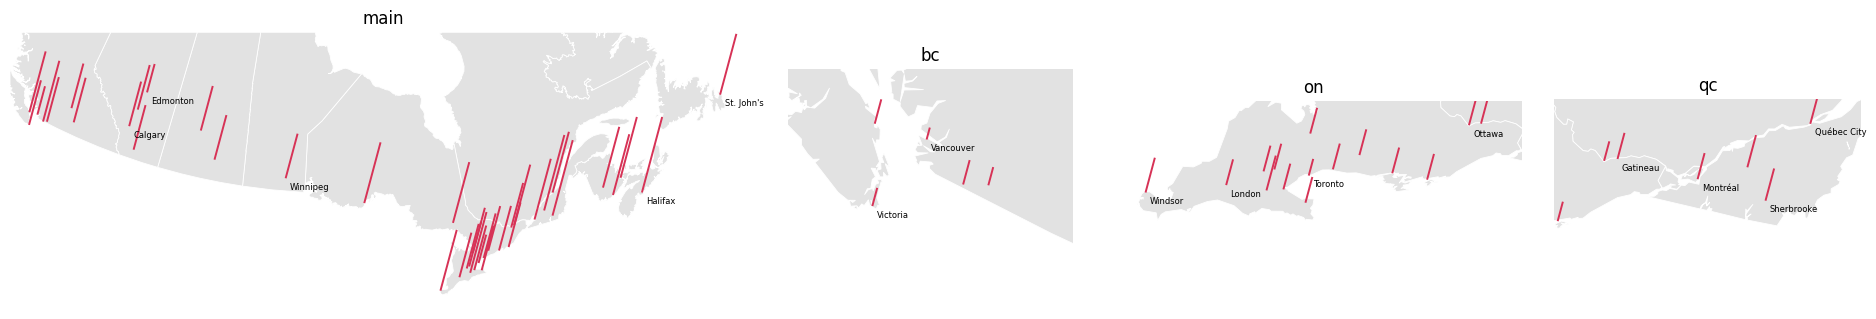

In [9]:
fig, axes = plt.subplots(1, len(frames), figsize=(19, 5), gridspec_kw={'width_ratios': [3.4, 1.3, 1.9, 1.4]})
for ax, fr, prv in zip(axes, frames, [main_prov] + [i['prov'] for i in INSETS]):
    prv.plot(ax=ax, color='#e2e2e2', edgecolor='white', linewidth=0.6)
    ext = fr['extent'] if fr['id'] == 'main' else fr['fit']
    pts = np.array([[p['x'], p['y']] for p in fr['points']]); idx = [p['i'] for p in fr['points']]
    scale_km = (ext[2] - ext[0]) / 700 * 55          # nominal 55 px at 700 px wide
    t = np.radians(ARROW_TILT_DEG)
    for (x, y), i in zip(pts, idx):
        L = len_frac[i] * scale_km * 1.3
        ax.plot([x, x + L * np.sin(t)], [y, y + L * np.cos(t)], color='#d73256', lw=1.4)
    for lab in fr['labels']:
        j = idx.index(lab['i']) if lab['i'] in idx else None
        if j is not None:
            ax.annotate(lab.get('text', net.loc[lab['i'], 'city']), pts[j], xytext=(3, -9), textcoords='offset points', fontsize=6)
    ax.set_xlim(ext[0], ext[2]); ax.set_ylim(ext[1], ext[3])
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(fr['id'])
plt.tight_layout()
plt.show()

### Export

One JSON file, `vis1_net_change_map.json`:

| key | contents |
|---|---|
| `meta` | measure description, baseline / latest quarter, city count, national and median net change, `arrow_tilt_deg` (chosen above), `class_breaks` / `class_breaks_real` (arrow size classes for each view), `real_dollar_year` |
| `cities` | one row per city, largest increase first: `city`, `province`, `base_rent`, `latest_rent`, `pct_change` (nominal), `real_base_rent` (the starting rent in latest-CPI dollars), `real_pct` (net change after inflation) |
| `frames` | the national frame (`id: "main"`) followed by the insets. Every frame has `provinces` GeoJSON, `points` (`i` = index into `cities`, `x`, `y` in that frame's km coordinates) and `labels` (label priority order, optional `text`). `main` also has `extent` and `key_anchor`; insets have `fit` (the visible box), `extent` (the clipped geometry, larger), `region` (the visible box outlined on the national map), `rotation`, `order`, `row` and `zoom` |

In [10]:
cities = net[['city', 'province', 'base_rent', 'latest_rent', 'pct_change', 'real_base_rent', 'real_pct']].to_dict(orient='records')

vis1 = {
    'meta': {
        'measure': f'Net change in {BED_LABEL} asking rent, {BASELINE_QUARTER} to {LATEST_QUARTER}',
        'baseline_quarter': BASELINE_QUARTER,
        'latest_quarter': LATEST_QUARTER,
        'bedroom': BED_LABEL,
        'n_cities': int(len(cities)),
        'national_pct_change': float(nat_pct),
        'median_pct_change': round(float(net['pct_change'].median()), 1),
        'min_pct_change': float(net['pct_change'].min()),
        'max_pct_change': float(net['pct_change'].max()),
        'arrow_tilt_deg': ARROW_TILT_DEG,
        'class_breaks': CLASS_BREAKS,
        'class_breaks_real': CLASS_BREAKS_REAL,
        'real_dollar_year': REAL_YEAR,
        'excluded': sorted(DISPLAY_NAME.get(k, k.title()) for k in skipped),
    },
    'cities': cities,
    'frames': frames,
}

out = OUT_DIR / 'vis1_net_change_map.json'
with open(out, 'w') as f:
    json.dump(vis1, f, ensure_ascii=False, separators=(',', ':'))
print(f'saved: {out}  ({out.stat().st_size / 1024:.0f} KB, {len(cities)} cities, {len(frames)} frames)')

saved: ../../src/data/falling-rents/vis1_net_change_map.json  (91 KB, 40 cities, 4 frames)


## VIS 2 — Trajectories of every city since 2019 (small multiples)

The same series as the map, but over time: for every CMA, the **net percentage change in 2-bedroom asking rent from Q1 2019 at each quarter**
(Q1 2019 = 0%), plus StatCan's Canada-wide aggregate (`all.csv`). Indexing every city to its own Q1 2019 puts them on one shared axis, so the
shape of the trend, not the level of rents, is what you compare.

The page shows Canada large (the size of four panels), then four large panels for big markets from across the country — Vancouver, Calgary, Toronto and Montréal — followed by every other city, A–Z, as tiny panels. Forty cities minus four featured leaves 36 tiny panels: four rows of nine on desktop, nine rows of four on a phone.
A faint Canada line is overlaid on each city panel.

Missing quarters stay `null` in the data (nothing is interpolated here); the page draws the line straight across them so it reads as one continuous trajectory.

In [11]:
# Featured cities, in display order after Canada: West / Prairies / Ontario / Quebec, large markets.
FEATURED = ['vancouver', 'calgary', 'toronto', 'montreal']
assert all(k in set(net['key']) for k in FEATURED)

import unicodedata
def sort_name(s):
    return unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode().lower()

def quarter_label_to_year(label):
    q, y = label.split()
    return int(y) + (int(q[1]) - 1) / 4

# The full quarterly grid, from the national file (every city shares it)
all_quarters = sorted(pd.read_csv(ASKING_ROOT / 'all.csv')['Quarter'], key=quarter_key)


def trajectory(series: pd.Series) -> list:
    """Net % change vs the baseline quarter at every quarter on the grid; None where the quarter is missing."""
    s = series.reindex(all_quarters)
    pct = (s / s[BASELINE_QUARTER] - 1) * 100
    return [None if pd.isna(v) else round(float(v), 1) for v in pct]


def series_record(name, values, base_rent, latest_rent):
    arr = np.array([np.nan if v is None else v for v in values])
    peak_i = int(np.nanargmax(arr))
    return {
        'city': name, 'values': values,
        'base_rent': int(base_rent), 'latest_rent': int(latest_rent),
        'latest': values[-1], 'peak': values[peak_i], 'peak_quarter': all_quarters[peak_i],
    }


canada = series_record('Canada', trajectory(nat), nat[BASELINE_QUARTER], nat.iloc[-1])

records = {}
for _, r in net.iterrows():
    s = load_series(ASKING_ROOT / f"{r['key']}.csv")
    records[r['key']] = series_record(r['city'], trajectory(s), r['base_rent'], r['latest_rent'])

featured = [records[k] for k in FEATURED]
others = sorted((rec for k, rec in records.items() if k not in FEATURED), key=lambda rec: sort_name(rec['city']))

all_vals = [v for rec in records.values() for v in rec['values'] if v is not None] + [v for v in canada['values'] if v is not None]
Y_DOMAIN = [int(np.floor(min(all_vals) / 10) * 10), int(np.ceil(max(all_vals) / 10) * 10)]
Y_TICKS  = [0, 50, 100]

year_ticks = [{'label': q.split()[1], 'i': i} for i, q in enumerate(all_quarters) if q.startswith('Q1')]

print(f'{len(all_quarters)} quarters ({all_quarters[0]} to {all_quarters[-1]}), y domain {Y_DOMAIN}')
print(f'featured: {[r["city"] for r in featured]}')
print(f'others ({len(others)}): {[r["city"] for r in others]}')
assert len(others) % 9 == 0 and len(others) % 4 == 0, 'the tiny panels should fill whole rows of 9 (desktop) and of 4 (phone)'
gaps = {rec['city']: [all_quarters[i] for i, v in enumerate(rec['values']) if v is None] for rec in records.values()}
print('missing quarters:', {k: v for k, v in gaps.items() if v})

# sanity checks used in the page copy
latest_vals = np.array([rec['latest'] for rec in records.values()])
peaks = np.array([rec['peak'] for rec in records.values()])
print(f'all {len(latest_vals)} cities above their Q1 2019 level now: {bool((latest_vals > 0).all())}')
print(f'below their own peak: {int((latest_vals < peaks - 0.05).sum())} of {len(latest_vals)}')
print(f'Canada: peak {canada["peak"]:+.1f}% in {canada["peak_quarter"]}, latest {canada["latest"]:+.1f}%')

29 quarters (Q1 2019 to Q1 2026), y domain [-20, 110]
featured: ['Vancouver', 'Calgary', 'Toronto', 'Montréal']
others (36): ['Abbotsford–Mission', 'Barrie', 'Belleville–Quinte West', 'Brantford', 'Chilliwack', 'Drummondville', 'Edmonton', 'Fredericton', 'Gatineau', 'Greater Sudbury', 'Guelph', 'Halifax', 'Hamilton', 'Kamloops', 'Kelowna', 'Kingston', 'Kitchener–Cambridge–Waterloo', 'Lethbridge', 'London', 'Moncton', 'Nanaimo', 'Oshawa', 'Ottawa', 'Peterborough', 'Québec City', 'Red Deer', 'Regina', 'Saint John', 'Saskatoon', 'Sherbrooke', 'St. Catharines–Niagara', "St. John's", 'Thunder Bay', 'Victoria', 'Windsor', 'Winnipeg']
missing quarters: {'Drummondville': ['Q2 2025'], "St. John's": ['Q2 2025'], 'Gatineau': ['Q2 2025'], 'Kelowna': ['Q2 2025']}
all 40 cities above their Q1 2019 level now: True
below their own peak: 35 of 40
Canada: peak +48.0% in Q4 2023, latest +41.4%


### Real-terms series and short names (for the toggle and the pop-ups)

Every series also gets its **after-inflation** trajectory (`values_real`: net change from Q1 2019 with each quarter's rent deflated by the CPI helpers above),
its peak in real terms, and the starting rent in latest-CPI dollars for the pop-up.

The tiny panels print each city's name above the graph in a small font, so long names get a short form that fits.

In [12]:
# ── Inflation adjustment for each series (CPI helpers and REAL_YEAR are defined above) ──
by_key = net.set_index('key')


def real_trajectory(nominal: pd.Series, column: str) -> list:
    """Net % change after inflation vs the baseline quarter, at every quarter on the grid (None where the quarter is missing)."""
    s = nominal.reindex(all_quarters)
    real = pd.Series({q: (v * real_factor(column, q) if pd.notna(v) else np.nan) for q, v in s.items()})
    pct = (real / real[BASELINE_QUARTER] - 1) * 100
    return [None if pd.isna(v) else round(float(v), 1) for v in pct]


def add_real(rec, nominal: pd.Series, column: str, real_base_rent, real_pct):
    vals = real_trajectory(nominal, column)
    arr = np.array([np.nan if v is None else v for v in vals])
    pi = int(np.nanargmax(arr))
    rec.update({'real_base_rent': int(real_base_rent), 'real_pct': float(real_pct),
                'values_real': vals, 'peak_real': vals[pi], 'peak_quarter_real': all_quarters[pi]})


f0c, f1c = real_factor('Canada', BASELINE_QUARTER), real_factor('Canada', LATEST_QUARTER)
add_real(canada, nat, 'Canada', round(nat[BASELINE_QUARTER] * f0c),
         round(((nat.iloc[-1] * f1c) / (nat[BASELINE_QUARTER] * f0c) - 1) * 100, 1))
for key, rec in records.items():
    add_real(rec, load_series(ASKING_ROOT / f'{key}.csv'), CMA_PROVINCE[key], by_key.loc[key, 'real_base_rent'], by_key.loc[key, 'real_pct'])
    assert abs(rec['values_real'][-1] - rec['real_pct']) < 0.15, (key, rec['values_real'][-1], rec['real_pct'])   # series and headline agree

# vertical scale for the after-inflation view (separate from the nominal one: real changes are smaller)
all_real_vals = [v for rec in [canada, *records.values()] for v in rec['values_real'] if v is not None]
Y_DOMAIN_REAL = [int(np.floor(min(all_real_vals) / 10) * 10), int(np.ceil(max(all_real_vals) / 10) * 10)]
Y_TICKS_REAL  = [0, 25, 50]
assert Y_DOMAIN_REAL[1] > Y_TICKS_REAL[-1]

# ── Short names for the tiny panels' captions ────────────────────────
SHORT_NAME = {
    'Abbotsford–Mission': 'Abbotsford', 'Belleville–Quinte West': 'Belleville', 'Greater Sudbury': 'Sudbury',
    'Kitchener–Cambridge–Waterloo': 'Kitchener', 'St. Catharines–Niagara': 'St. Catharines',
}
for rec in [canada, *records.values()]:
    rec['short'] = SHORT_NAME.get(rec['city'], rec['city'])
assert max(len(r['short']) for r in records.values()) <= 14, 'a caption is too long for a tiny panel'

# alphabetical by the name the page prints (so 'Greater Sudbury', shown as 'Sudbury', sorts under S)
others.sort(key=lambda r: sort_name(r['short']))

print(f'real y domain {Y_DOMAIN_REAL}; Canada: {canada["latest"]:+.1f}% nominal vs {canada["real_pct"]:+.1f}% real (peak {canada["peak_real"]:+.1f}% in {canada["peak_quarter_real"]})')
check = pd.DataFrame([{'city': r['city'], 'nominal %': r['latest'], 'real %': r['real_pct'], 'peak real %': r['peak_real'], 'peak real q': r['peak_quarter_real']} for r in records.values()])
print(check.sort_values('real %').head(5).to_string(index=False))

real y domain [-20, 70]; Canada: +41.4% nominal vs +16.6% real (peak +26.0% in Q4 2023)
     city  nominal %  real %  peak real % peak real q
  Toronto        3.9   -14.1          0.0     Q1 2019
Vancouver       24.5     2.6         23.4     Q3 2023
 Edmonton       24.4     2.9          7.7     Q1 2024
 Winnipeg       35.2    11.8         11.8     Q1 2026
   Ottawa       37.4    13.6         20.9     Q1 2025


### Quick visual check

Static preview of the featured panels and the tiny multiples (the real graphic is drawn in Svelte).

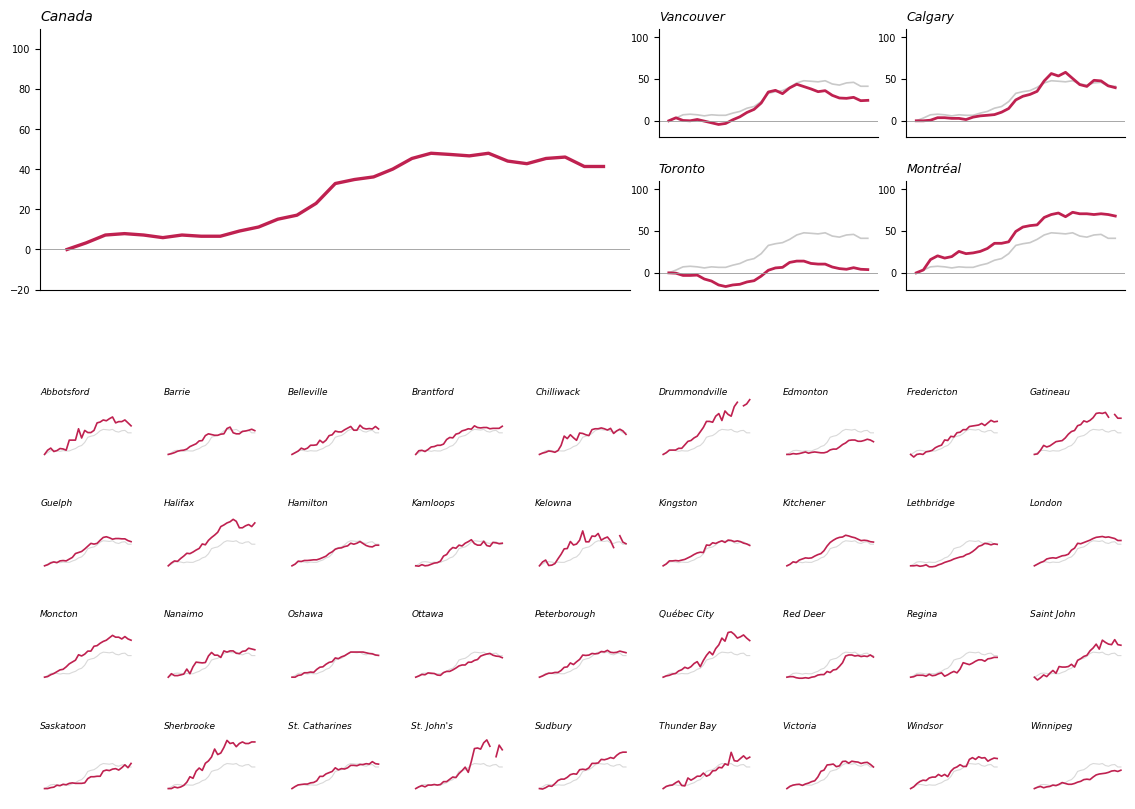

In [13]:
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(7, 9, height_ratios=[1.6, 1.6, 0.3, 1, 1, 1, 1], hspace=0.6, wspace=0.3)
xs = np.arange(len(all_quarters))
nat_v = np.array([np.nan if v is None else v for v in canada['values']])
vals_of = lambda r: np.array([np.nan if v is None else v for v in r['values']])


def style(ax, title, size):
    ax.axhline(0, color='#999', lw=.6); ax.set_ylim(Y_DOMAIN); ax.set_xticks([]); ax.tick_params(labelsize=7)
    ax.set_title(title, fontsize=size, loc='left', style='italic')
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)


# Canada: the size of four panels (2 x 2), with the four featured cities in the other half
ax = fig.add_subplot(gs[0:2, 0:5]); ax.plot(xs, nat_v, color='#bf2150', lw=2.4); style(ax, 'Canada', 10)
for n, r in enumerate(featured):
    cols = slice(5, 7) if n % 2 == 0 else slice(7, 9)
    ax = fig.add_subplot(gs[n // 2, cols])
    ax.plot(xs, nat_v, color='#c9c9c9', lw=1.2); ax.plot(xs, vals_of(r), color='#bf2150', lw=2); style(ax, r['city'], 9)

for n, r in enumerate(others):                                  # 36 tiny panels: 4 rows of 9
    ax = fig.add_subplot(gs[3 + n // 9, n % 9])
    ax.plot(xs, nat_v, color='#d9d9d9', lw=.8); ax.plot(xs, vals_of(r), color='#bf2150', lw=1.2)
    ax.set_ylim(Y_DOMAIN); ax.axis('off'); ax.set_title(r['short'], fontsize=6.5, loc='left', style='italic', pad=2)
plt.show()

### Export

`vis2_city_trajectories.json`:

| key | contents |
|---|---|
| `meta` | `quarters` (the shared x grid, oldest first), `year_ticks` (`{label, i}` for each Q1), `y_domain`, `y_ticks`, `real_dollar_year` (CPI base year for the inflation-adjusted rents), `y_domain_real` / `y_ticks_real` (vertical scale of the after-inflation view), baseline / latest quarter, bedroom type, number of cities |
| `canada` | the Canada-wide series |
| `featured` | four featured cities, in display order |
| `others` | every other city, alphabetical |

Each series: `city`, `values` (net % change vs Q1 2019 at each quarter, `null` where missing), `short` (caption), `base_rent`, `latest_rent`, `latest`, `peak`, `peak_quarter` (all nominal), and the after-inflation counterparts: `values_real`, `real_base_rent` (the starting rent in latest-CPI dollars), `real_pct`, `peak_real`, `peak_quarter_real`.

In [14]:
vis2 = {
    'meta': {
        'measure': f'Net change in {BED_LABEL} asking rent since {BASELINE_QUARTER}',
        'baseline_quarter': BASELINE_QUARTER,
        'latest_quarter': LATEST_QUARTER,
        'bedroom': BED_LABEL,
        'n_cities': int(len(records)),
        'quarters': all_quarters,
        'year_ticks': year_ticks,
        'y_domain': Y_DOMAIN,
        'y_ticks': Y_TICKS,
        'real_dollar_year': REAL_YEAR,
        'y_domain_real': Y_DOMAIN_REAL,
        'y_ticks_real': Y_TICKS_REAL,
    },
    'canada': canada,
    'featured': featured,
    'others': others,
}

out2 = OUT_DIR / 'vis2_city_trajectories.json'
with open(out2, 'w') as f:
    json.dump(vis2, f, ensure_ascii=False, separators=(',', ':'))
print(f'saved: {out2}  ({out2.stat().st_size / 1024:.0f} KB, {len(records)} cities + Canada, {len(all_quarters)} quarters)')

saved: ../../src/data/falling-rents/vis2_city_trajectories.json  (21 KB, 40 cities + Canada, 29 quarters)


## VIS 3 — How much did rents paid change each year? (stacked histogram)

Everything above is about **asking** rents. This graphic is about the other side of the argument — the rent in apartments that are
already occupied — using CMHC's October Rental Market Survey (`primary-summary`, "Average Rent", all unit types, purpose-built rentals).

For every city and every year from 2019 to 2025 we take the percentage change in the average rent since the previous October, and count
**city-years** in 1-percentage-point bins. In the graphic each bar is one bin and each colour is one year, so a bar's height is the number of
cities whose rent rose by that much, split by year.

- Cities: every CMA with a complete 2018–2025 series (40; Windsor, St. Catharines–Niagara are not in the primary-summary extract) = 280 city-years.
- Bins are `[lo, lo + 1)` on the **1-decimal rounded** change, so a bar's label always matches the values in its pop-up.
- **After inflation** uses the same provincial CPI as the rest of the page (annual CPI at Q2, interpolated to quarters; October ≈ Q4). CPI stops in 2025 and is
  held flat after it, so the 2025 real change is a little too high.
- Both views share one horizontal range and one vertical scale, so nothing moves when the reader toggles.
- Why not CMHC's own same-sample "% Change" column? It is suppressed in some city-years (`**`) and flagged "not statistically different from zero" (`++`) in others, which the cleaning step turns into 0.0.
  The change in the average rent is complete for every city-year; the two differ by ~0.8 points in the median (see Section 7 of `explore_falling_rents.ipynb`).

In [15]:
# ── VIS 3: annual change in average rent, CMHC occupied purpose-built rentals ─────────────────────────────────────────
CMHC_SUMMARY_ROOT = Path('../../data/cmhc-rental-clean/can-cma-primary/primary-summary')
CMHC_TO_STATCAN   = {'quebec city': 'quebec', "st john's": "st. john's"}      # CMHC filename -> StatCan spelling used everywhere else here
VIS3_YEARS        = list(range(2019, 2026))
BIN_WIDTH         = 1                                                        # percentage points


def cpi_q4(column: str, year: int) -> float:
    s = cpi_q[column]
    return float(s[min(pd.Period(f'{year}Q4'), s.index.max())])


recs = []
for fp in sorted(CMHC_SUMMARY_ROOT.glob('*.csv')):
    key = CMHC_TO_STATCAN.get(fp.stem, fp.stem)
    df = pd.read_csv(fp)
    if df.empty:
        continue
    avg = df.set_index('Year')['Average Rent'].dropna()
    if not all(y in avg.index for y in [VIS3_YEARS[0] - 1] + VIS3_YEARS):
        print('skipped (incomplete 2018-2025):', fp.stem)
        continue
    name = DISPLAY_NAME.get(key, key.title())
    for y in VIS3_YEARS:
        nominal = (avg[y] / avg[y - 1] - 1) * 100
        infl = cpi_q4(CMA_PROVINCE[key], y) / cpi_q4(CMA_PROVINCE[key], y - 1)
        real = ((1 + nominal / 100) / infl - 1) * 100
        recs.append({'city': name, 'year': y, 'nominal': round(float(nominal), 1), 'real': round(float(real), 1)})

changes = pd.DataFrame(recs)
N_CITIES = changes['city'].nunique()
assert len(changes) == N_CITIES * len(VIS3_YEARS)

# One shared x range for both views (whole percentage points), and bins [lo, lo + 1)
X_LO = int(np.floor(changes[['nominal', 'real']].min().min()))
X_HI = int(np.floor(changes[['nominal', 'real']].max().max())) + BIN_WIDTH
BIN_EDGES = list(range(X_LO, X_HI, BIN_WIDTH))
for col in ['nominal', 'real']:
    changes[f'{col}_bin'] = np.floor(changes[col] / BIN_WIDTH).astype(int) * BIN_WIDTH

def bin_table(col):
    """For each bin, a list per year of [city, change] pairs (largest change first)."""
    out = []
    for lo in BIN_EDGES:
        per_year = []
        for y in VIS3_YEARS:
            sub = changes[(changes['year'] == y) & (changes[f'{col}_bin'] == lo)].sort_values(col, ascending=False)
            per_year.append([[r['city'], float(r[col])] for _, r in sub.iterrows()])
        out.append(per_year)
    return out

nominal_bins, real_bins = bin_table('nominal'), bin_table('real')
stack_heights = [[sum(len(y) for y in b) for b in tbl] for tbl in (nominal_bins, real_bins)]
Y_MAX = int(np.ceil(max(max(h) for h in stack_heights) / 5) * 5)
Y_TICKS = list(range(0, Y_MAX, 10))

print(f'{N_CITIES} cities x {len(VIS3_YEARS)} years = {len(changes)} city-years;  x range {X_LO} to {X_HI} ({len(BIN_EDGES)} bins);  y max {Y_MAX}')
print('declines (nominal / real):', int((changes['nominal'] < 0).sum()), '/', int((changes['real'] < 0).sum()))
print('median change (nominal / real):', changes['nominal'].median().round(1), '/', changes['real'].median().round(1))
print('by year, declines nominal:', changes[changes['nominal'] < 0].groupby('year').size().to_dict(), '| real:', changes[changes['real'] < 0].groupby('year').size().to_dict())

skipped (incomplete 2018-2025): windsor


40 cities x 7 years = 280 city-years;  x range -9 to 23 (32 bins);  y max 35
declines (nominal / real): 5 / 47
median change (nominal / real): 6.0 / 3.1
by year, declines nominal: {2019: 1, 2020: 1, 2021: 1, 2022: 1, 2023: 1} | real: {2019: 3, 2020: 5, 2021: 20, 2022: 15, 2023: 1, 2024: 2, 2025: 1}


### Quick visual check

Static preview of both views (the real graphic is drawn in Svelte, with this page's colour ramp: amber = 2019, purple = 2025).

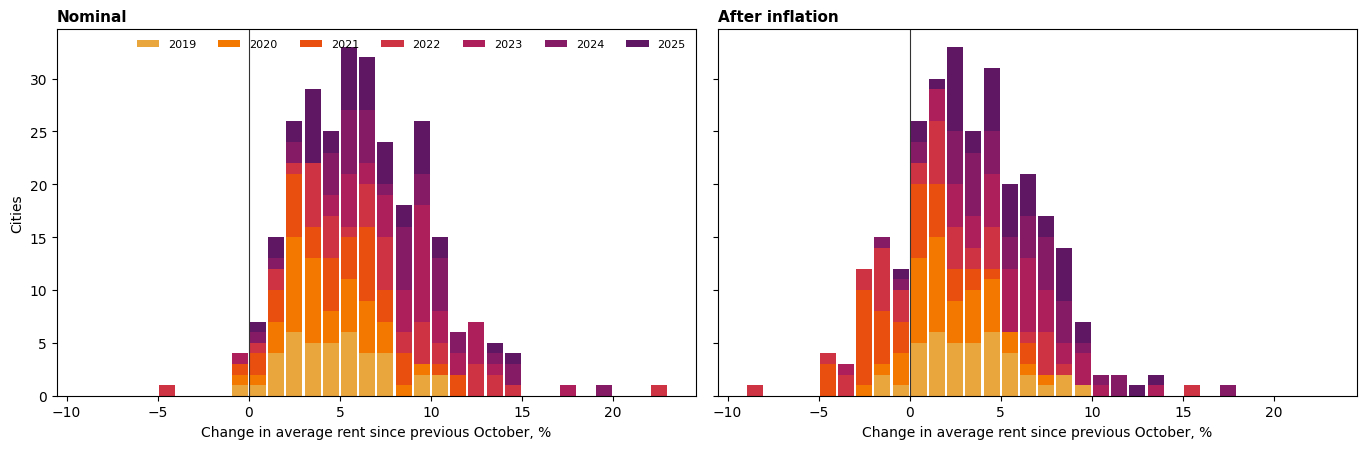

In [16]:
VIS3_RAMP = ['#e8a63d', '#f37800', '#e94f0f', '#ce3344', '#ad1f5b', '#861b65', '#5f1764']   # mirrors YEAR_COLORS in the Svelte chart

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (col, tbl) in zip(axes, [('nominal', nominal_bins), ('real', real_bins)]):
    bottom = np.zeros(len(BIN_EDGES))
    for yi, y in enumerate(VIS3_YEARS):
        counts = np.array([len(b[yi]) for b in tbl])
        ax.bar(np.array(BIN_EDGES) + BIN_WIDTH / 2, counts, bottom=bottom, width=BIN_WIDTH * 0.88, color=VIS3_RAMP[yi], label=str(y))
        bottom += counts
    ax.axvline(0, color='#333', lw=0.8)
    ax.set_title({'nominal': 'Nominal', 'real': 'After inflation'}[col], loc='left', fontsize=11, fontweight='bold')
    ax.set_xlabel('Change in average rent since previous October, %')
axes[0].set_ylabel('Cities')
axes[0].legend(ncol=7, frameon=False, fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

### Export

`vis3_rent_change_histogram.json`:

| key | contents |
|---|---|
| `meta` | `years` (stack order, bottom to top), `bin_width`, `x_domain` (`[lo, hi]`, whole percentage points, shared by both views), `x_ticks`, `y_max` / `y_ticks` (shared by both views), `n_cities`, `n_city_years`, `declines` (count of city-years below zero, per view), `medians`, source / measure text |
| `bins` | one entry per bin, left to right: `lo`, `hi`, and for each view (`nominal`, `real`) a list with one item per year, each a list of `[city, change %]` pairs, largest first. A segment's height is the length of its list. |

In [17]:
vis3 = {
    'meta': {
        'measure': 'Change in average rent since the previous October',
        'source': 'CMHC Rental Market Survey, average rent, purpose-built rentals (all unit types)',
        'years': VIS3_YEARS,
        'bin_width': BIN_WIDTH,
        'x_domain': [X_LO, X_HI],
        'x_ticks': [t for t in range(-10, X_HI + 1) if t % 5 == 0 and X_LO <= t <= X_HI],
        'y_max': Y_MAX,
        'y_ticks': Y_TICKS,
        'n_cities': int(N_CITIES),
        'n_city_years': int(len(changes)),
        'declines': {'nominal': int((changes['nominal'] < 0).sum()), 'real': int((changes['real'] < 0).sum())},
        'medians': {'nominal': float(changes['nominal'].median().round(1)), 'real': float(changes['real'].median().round(1))},
        'real_dollar_year': REAL_YEAR,
    },
    'bins': [
        {'lo': lo, 'hi': lo + BIN_WIDTH, 'nominal': nominal_bins[i], 'real': real_bins[i]}
        for i, lo in enumerate(BIN_EDGES)
    ],
}

out3 = OUT_DIR / 'vis3_rent_change_histogram.json'
with open(out3, 'w') as f:
    json.dump(vis3, f, ensure_ascii=False, separators=(',', ':'))
print(f'saved: {out3}  ({out3.stat().st_size / 1024:.0f} KB, {len(BIN_EDGES)} bins, {len(changes)} city-years)')

saved: ../../src/data/falling-rents/vis3_rent_change_histogram.json  (13 KB, 32 bins, 280 city-years)


## VIS 4 — Do headlines about falling rents give any context? (one tick per headline)

The last graphic compares **news headlines** about falling and rising rents. Each headline is one tick; ticks are grouped into a bar per direction
and split into those that give the reader some context beyond the bare direction of change and those with little or none.

Source: `data/rent_headlines/exploratory/headline_context_for_review.csv`, written by `analysis/falling-rents/explore_rent_headlines.ipynb`
(Media Cloud headlines containing "rent"/"rents", 2019 to March 2026; each headline classified for direction and context by a language model, with the falling headlines
independently re-checked in a blind second pass).

- **Some context** = at least one of six flags is set: `magnitude` (says the change is small/slowing), `historical` (compared with an earlier year),
  `peak` (relative to a peak/record), `current_level` (says rents are still high), `affordability` (still unaffordable), `contrasting_geography` (the opposite trend elsewhere).
  `numerical` (a bare % or $ figure) does **not** count. This is the notebook's "any meaningful context" measure; it is recomputed here from the six flags, so hand edits to the CSV flow through.
- **Falling** = every validated falling headline (the full set). **Rising** = the random sample used for the symmetry check (not independently re-validated, so the flags are first-pass only).
- Order inside each bar: context ticks first, then the rest; oldest to newest within each.

In [18]:
# ── VIS 4: headline context, one tick per headline ────────────────────────────────────────────────────────────────────
REVIEW_CSV = Path('../../data/rent_headlines/exploratory/headline_context_for_review.csv')

CONTEXT_FLAGS = ['magnitude', 'historical', 'peak', 'current_level', 'affordability', 'contrasting_geography']   # "numerical" deliberately excluded
FLAG_LABELS = {
    'magnitude':             'Says the change is small or slowing',
    'historical':            'Compares with an earlier year',
    'peak':                  'Compares with a peak or record',
    'current_level':         'Says rents are still high',
    'affordability':         'Says rents are still unaffordable',
    'contrasting_geography': 'Notes the opposite trend elsewhere',
}
OUTLET_NAMES = {
    'thestar.com': 'Toronto Star', 'ctvnews.ca': 'CTV News', 'globalnews.ca': 'Global News', 'theglobeandmail.com': 'The Globe and Mail',
    'cbc.ca': 'CBC', 'winnipegfreepress.com': 'Winnipeg Free Press', 'thespec.com': 'The Hamilton Spectator', 'kelownadailycourier.ca': 'Kelowna Daily Courier',
    'vancouversun.com': 'Vancouver Sun', 'reddeeradvocate.com': 'Red Deer Advocate', 'torontosun.com': 'Toronto Sun', 'bclocalnews.com': 'BC Local News',
    'niagarafallsreview.ca': 'Niagara Falls Review', 'lfpress.com': 'London Free Press', 'therecord.com': 'Waterloo Region Record', 'abbynews.com': 'Abbotsford News',
    'timescolonist.com': 'Times Colonist', 'trailtimes.ca': 'Trail Times', 'wellandtribune.ca': 'Welland Tribune', 'theconversation.com': 'The Conversation',
    'pentictonherald.ca': 'Penticton Herald', 'brandonsun.com': 'Brandon Sun', 'troymedia.com': 'Troy Media', 'calgaryherald.com': 'Calgary Herald',
    'nationalpost.com': 'National Post', 'nationalnewswatch.com': 'National Newswatch', 'cbj.ca': 'Canadian Business Journal', 'montrealgazette.com': 'Montreal Gazette',
    'edmontonjournal.com': 'Edmonton Journal', 'bnnbloomberg.ca': 'BNN Bloomberg', 'kimberleybulletin.com': 'Kimberley Bulletin', 'moneysense.ca': 'MoneySense',
    'medicinehatnews.com': 'Medicine Hat News', 'nationalobserver.com': 'National Observer', 'rabble.ca': 'rabble.ca', 'canadianbusiness.com': 'Canadian Business',
    'tj.news': 'Trail Times / TJ News',
}

hl = pd.read_csv(REVIEW_CSV)
hl['gives_context'] = hl[CONTEXT_FLAGS].astype(bool).any(axis=1)
mismatch = int((hl['gives_context'] != hl['any_meaningful_context'].astype(bool)).sum())
print(f'rows where the recomputed context flag differs from the CSV column: {mismatch} (non-zero only if the flags were hand-edited)')
unnamed = sorted(set(hl['outlet']) - set(OUTLET_NAMES))
assert not unnamed, f'add display names for: {unnamed}'

groups = []
for gid, label in [('falling', 'Rents falling'), ('rising', 'Rents rising')]:
    g = hl[hl['direction_group'] == gid].copy()
    g = g.sort_values(['gives_context', 'date', 'row_id'], ascending=[False, True, True])
    items = [
        {'t': r.headline, 'o': OUTLET_NAMES[r.outlet], 'd': r.date, 'u': r.url,
         'c': int(r.gives_context), 'f': [f for f in CONTEXT_FLAGS if getattr(r, f)]}
        for r in g.itertuples()
    ]
    groups.append({'id': gid, 'label': label, 'n': len(items), 'n_context': int(g['gives_context'].sum()),
                   'share': round(float(g['gives_context'].mean() * 100), 1), 'headlines': items})

vis4 = {
    'meta': {
        'flag_labels': FLAG_LABELS,
        'n_headlines': int(len(hl)),
        'date_range': [str(hl['date'].min()), str(hl['date'].max())],
        'n_outlets': int(hl['outlet'].nunique()),
    },
    'groups': groups,
}
out4 = OUT_DIR / 'vis4_headline_context.json'
with open(out4, 'w') as f:
    json.dump(vis4, f, ensure_ascii=False, separators=(',', ':'))
print(f'saved: {out4}  ({out4.stat().st_size / 1024:.0f} KB)')
for g in groups:
    print(f"  {g['id']:8s} {g['n']} headlines, {g['n_context']} give context ({g['share']}%)")

rows where the recomputed context flag differs from the CSV column: 0 (non-zero only if the flags were hand-edited)
saved: ../../src/data/falling-rents/vis4_headline_context.json  (73 KB)
  falling  149 headlines, 24 give context (16.1%)
  rising   143 headlines, 67 give context (46.9%)
